# Map distances and policy priorities within political self-placement

This notebook extends notebook 19 with a global concordance analysis and a
second, discovery-selected case among participants reporting self-placement 7.
The self-placement-3 case remains frozen. All results use existing Chilean maps
and decisions excluded from their training. No DYNAMAP model is retrained here.

**Inputs:** the release's Chilean observations, original train/test assignments,
retained metadata and age decisions, the five positive-symmetric 2D maps, and
the frozen case-3 inputs in `data/processed/map_interpretation`.
**Outputs:** three figures in `outputs/figures`, generating CSV/Parquet tables
in `outputs/tables`, structured LaTeX summaries in `outputs/manuscript_tables`,
and provenance in `outputs/diagnostics`. All new filenames start with `map20_`.
Open from the release root or `notebooks/` and run in a fresh kernel.

The evaluation is secondary: historical test data have been consulted before.
Agreement and relative priority are associations, not causal effects, absolute
support, natural political classes or independent replications across seeds.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import time
import numpy as np
import pandas as pd
import scipy
from scipy.stats import rankdata
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
import textwrap

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/Chile_pairs.parquet').is_file(), 'Open from the release root or notebooks/.'
DATA = ROOT / 'data'
MODELS = ROOT / 'outputs/models'
CASE3 = DATA / 'processed/map_interpretation'
TABLES = ROOT / 'outputs/tables'
LATEX = ROOT / 'outputs/manuscript_tables'
FIGURES = ROOT / 'outputs/figures'
DIAGNOSTICS = ROOT / 'outputs/diagnostics'
for directory in [TABLES, LATEX, FIGURES, DIAGNOSTICS]:
    directory.mkdir(parents=True, exist_ok=True)

SEEDS = [101, 201, 301, 401, 501]
PRIMARY_SEED = 101
RANDOM_SEED = 20261015
GLOBAL_BOOTSTRAPS = 1000
POSITION_PERMUTATIONS = 499
CASE_BOOTSTRAPS = 2000
N_BINS = 5
PRIORITY_CUTOFF = 30
DISTINCTIVE_GAP = 10
SHARED_GAP = 5
MIN_PEOPLE = 30
MIN_SHARED_OPPONENTS = 10
PHASE_SALT = 'dynamap-within-label-20261014:'
SECTORS = ['Near', 'Middle', 'Far']
COLORS = {'Near': '#0072B2', 'Middle': '#bdbdbd', 'Far': '#D55E00'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'pdf.fonttype': 42, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white',
                     'axes.facecolor': 'white'})

def show_table(table, name, publication=False):
    """Display the live dataframe, then export that same object."""
    display(table)
    table.to_csv(TABLES / f'map20_{name}.csv', index=False)
    if publication:
        table.to_latex(LATEX / f'map20_{name}.tex', index=False,
                       escape=True, float_format='%.3f')

def show_figure(figure, name):
    display(figure)
    figure.savefig(FIGURES / f'map20_{name}.pdf', bbox_inches='tight')
    figure.savefig(FIGURES / f'map20_{name}.png', bbox_inches='tight', dpi=220)
    plt.close(figure)

input_paths = []
def input_file(relative_path):
    path = ROOT / relative_path
    assert path.is_file(), str(path)
    if path not in input_paths:
        input_paths.append(path)
    return path

coordinates = {}
proposal_coordinates = {}
for seed in SEEDS:
    user_coordinate_path = input_file(f'outputs/models/Chile_dim2_seed{seed}/coordsU.csv')
    proposal_coordinate_path = input_file(f'outputs/models/Chile_dim2_seed{seed}/coordsP.csv')
    people_map = pd.read_csv(user_coordinate_path, float_precision='round_trip')
    proposal_map = pd.read_csv(proposal_coordinate_path, float_precision='round_trip')
    assert people_map.uuid.is_unique and proposal_map.id.is_unique
    assert len(people_map) == 47574 and len(proposal_map) == 90
    if seed == PRIMARY_SEED:
        user_ids = people_map.uuid.to_numpy()
        proposal_ids = proposal_map.id.to_numpy()
    assert np.array_equal(people_map.uuid, user_ids)
    assert np.array_equal(proposal_map.id, proposal_ids)
    coordinates[seed] = people_map[['z1', 'z2']].to_numpy()
    proposal_coordinates[seed] = proposal_map[['z1', 'z2']].to_numpy()
user_index = pd.Series(np.arange(len(user_ids)), index=user_ids)
proposal_index = pd.Series(np.arange(len(proposal_ids)), index=proposal_ids)
texts = pd.read_csv(input_file('data/raw/chile_labels.tsv'), sep='\t').set_index('id')
assert texts.index.is_unique and set(proposal_ids).issubset(texts.index)

age = pd.read_csv(input_file('data/processed/participant_age_decisions.csv'))
age = age.loc[age.country.eq('Chile')].set_index('uuid')
assert age.index.is_unique and age.loc[user_ids, 'include'].eq(True).all()
metadata = pd.read_csv(input_file('data/processed/figure_inputs/spatial/Chile_metadata.csv'))
labels = metadata[['uuid', 'politica']].drop_duplicates()
labels = labels.loc[labels.uuid.isin(user_ids) & labels.politica.isin(range(11))].copy()
conflicting = labels.groupby('uuid').politica.nunique().loc[lambda s: s > 1].index
labels = labels.loc[~labels.uuid.isin(conflicting)].copy()
assert labels.uuid.is_unique
labels['politica'] = labels.politica.astype(int)
labels['u'] = labels.uuid.map(user_index).astype(int)
labels['phase'] = labels.uuid.map(lambda value: 'discovery' if int(hashlib.sha256((PHASE_SALT + value).encode()).hexdigest()[:16], 16) < 2**63 else 'confirmation')
labels = labels.sort_values('u').reset_index(drop=True)

# Verify the unchanged original case-3 population and participant partition.
case3_people = pd.read_csv(input_file('data/processed/map_interpretation/participants.csv'))
assert set(case3_people.uuid) == set(labels.loc[labels.politica.eq(3), 'uuid'])
pd.testing.assert_frame_equal(case3_people[['uuid', 'u', 'phase']].sort_values('u').reset_index(drop=True),
                              labels.loc[labels.politica.eq(3), ['uuid', 'u', 'phase']].reset_index(drop=True), check_dtype=False)

pairs = pd.read_parquet(input_file('data/processed/Chile_pairs.parquet'))
split = pd.read_parquet(input_file('data/processed/Chile_split_assignments.parquet'))
assert pairs.id.is_unique and split.id.is_unique and len(pairs) == len(split) == 2970347
pairs = pairs.merge(split, on=['id', 'uuid'], validate='one_to_one', how='left')
assert pairs.split.isin(['train', 'test']).all()
pairs['u'] = pairs.uuid.map(user_index)
assert pairs.u.notna().all()
pairs['u'] = pairs.u.astype(int)
pairs['a'] = pairs.option_a.map(proposal_index).astype(int)
pairs['b'] = pairs.option_b.map(proposal_index).astype(int)
pairs['lo'] = np.minimum(pairs.a, pairs.b)
pairs['hi'] = np.maximum(pairs.a, pairs.b)
assert pairs.a.ne(pairs.b).all()
assert not pairs.duplicated(['u', 'lo', 'hi']).any(), 'Duplicate person / alternative pair.'
assert (pairs.selected.eq(pairs.option_a) | pairs.selected.eq(pairs.option_b)).all()
assert set(pairs.loc[pairs.split.eq('train'), 'u']) == set(range(len(user_ids)))
test = pairs.loc[pairs.split.eq('test')].merge(labels[['u', 'politica', 'phase']], on='u', validate='many_to_one')
test = test.rename(columns={'politica': 'label'}).reset_index(drop=True)
exposure = test.drop(columns=['selected']).copy()
sample_counts = labels.groupby(['politica', 'phase']).size().rename('participants').reset_index()
choice_counts = exposure.groupby(['label', 'phase']).size().rename('test_choices').reset_index()
sample_counts = sample_counts.merge(choice_counts, left_on=['politica', 'phase'], right_on=['label', 'phase'], validate='one_to_one').drop(columns='label')
show_table(sample_counts, 'sample_counts')
checks = pd.DataFrame([{'check': 'retained_map_people', 'value': len(user_ids)},
                       {'check': 'retained_choices', 'value': len(pairs)},
                       {'check': 'unambiguous_self_placement_people', 'value': len(labels)},
                       {'check': 'conflicting_self_placement_people_excluded', 'value': len(conflicting)},
                       {'check': 'self_placement_5_included', 'value': int(labels.politica.eq(5).sum())},
                       {'check': 'duplicate_person_pair', 'value': 0}])
show_table(checks, 'input_checks')
show_table(labels, 'participant_partitions')

,politica,phase,participants,test_choices
0,0,confirmation,745,5498
1,0,discovery,735,5369
2,1,confirmation,599,4249
3,1,discovery,577,4323
4,2,confirmation,1606,11705
5,2,discovery,1582,11359
6,3,confirmation,1870,13908
7,3,discovery,1825,13581
8,4,confirmation,1337,10533
9,4,discovery,1323,9896


,check,value
0,retained_map_people,47574
1,retained_choices,2970347
2,unambiguous_self_placement_people,37100
3,conflicting_self_placement_people_excluded,536
4,self_placement_5_included,15565
5,duplicate_person_pair,0


,uuid,politica,u,phase
0,000057c7-295c-4a61-8f62-76aff62bf079,8,0,discovery
1,000059b8-10b9-4f74-9c01-80bd2c48f509,5,1,discovery
2,00032199-2183-48c0-8f0d-ac37dc8ece60,6,2,confirmation
3,000629ba-44c0-47c1-b2b2-abe4f0ee808f,3,3,discovery
4,0006b923-77a6-40c1-95e0-f98b817bcab2,3,4,discovery
...,...,...,...,...
37095,fff8a6be-746b-4d24-9148-73c8c6accb69,3,47569,confirmation
37096,fffa9813-765b-46c6-87f6-47fa854e784f,5,47570,confirmation
37097,fffcdf0e-0c78-40f7-915a-d41d6650c99b,2,47571,confirmation
37098,fffe76d8-ea19-4360-8050-1aadfb982c54,5,47572,confirmation


## Freeze case selection before evaluating outcomes

Case 3 retains notebook 19's anchor, sectors and six proposals. For case 7,
choose the proposal with the greatest median rank IQR across the five discovery
maps, among proposals with at least 30 discovery test participants in each
extreme distance tercile and 10 shared opponents. This support check uses only
exposure, never which proposal was chosen. Ties are broken by proposal ID.

Each case then uses one anchor to define all sectors. Select its anchor, up to
two distinctive proposals per extreme (mean rank <=30, advantage >=10), and one
shared-priority proposal (both mean ranks <=30, absolute gap <=5). Preserve the
same sorting as notebook 19. Do not replace a proposal after seeing its outcome.

In [2]:
case_people = {3: case3_people, 7: labels.loc[labels.politica.eq(7)].copy().reset_index(drop=True)}
case_distances, case_rankings = {}, {}
for label in [3, 7]:
    for seed in SEEDS:
        if label == 3:
            # Use the exact frozen coordinate serialization supplied for notebook 19.
            cu = pd.read_csv(input_file(f'data/processed/map_interpretation/{seed}/coordinates.csv'), float_precision='round_trip')
            cp = pd.read_csv(input_file(f'data/processed/map_interpretation/{seed}/proposals.csv'), float_precision='round_trip')
            assert cu.uuid.tolist() == case_people[3].uuid.tolist()
            assert cp.id.tolist() == proposal_ids.tolist()
            xyz, pxyz = cu[['z1', 'z2']].to_numpy(), cp[['z1', 'z2']].to_numpy()
            assert np.max(np.abs(xyz - coordinates[seed][cu.u.to_numpy()])) < 1e-12
        else:
            xyz = coordinates[seed][case_people[label].u.to_numpy()]
            pxyz = proposal_coordinates[seed]
        distance = np.linalg.norm(xyz[:, None, :] - pxyz[None, :, :], axis=2)
        case_distances[label, seed] = distance
        case_rankings[label, seed] = rankdata(distance, axis=1, method='average')

disc7 = case_people[7].phase.eq('discovery').to_numpy()
exposure7 = exposure.loc[exposure.label.eq(7) & exposure.phase.eq('discovery')].copy()
iqr7 = np.stack([np.diff(np.quantile(case_rankings[7, seed][disc7], [.25, .75], axis=0), axis=0)[0] for seed in SEEDS])
anchor_candidates = []
for j, proposal_id in enumerate(proposal_ids):
    distance = case_distances[7, PRIMARY_SEED][:, j]
    lower, upper = np.quantile(distance[disc7], [1/3, 2/3])
    sector = np.where(distance <= lower, 'Near', np.where(distance >= upper, 'Far', 'Middle'))
    f = exposure7.loc[exposure7.option_a.eq(proposal_id) | exposure7.option_b.eq(proposal_id)].copy()
    f['sector'] = f.u.map(pd.Series(sector, index=case_people[7].u))
    f = f.loc[f.sector.isin(['Near', 'Far'])]
    f['opponent'] = np.where(f.option_a.eq(proposal_id), f.option_b, f.option_a)
    counts = f.groupby('sector').u.nunique()
    shared = int(f.groupby('opponent').sector.nunique().eq(2).sum())
    row = {'proposal_id': int(proposal_id), 'median_rank_iqr': float(np.median(iqr7[:, j])),
           'near_people': int(counts.get('Near', 0)), 'far_people': int(counts.get('Far', 0)),
           'shared_opponents': shared, 'proposal': texts.loc[proposal_id, 'name']}
    row['eligible'] = row['near_people'] >= MIN_PEOPLE and row['far_people'] >= MIN_PEOPLE and shared >= MIN_SHARED_OPPONENTS
    anchor_candidates.append(row)
anchor_candidates = pd.DataFrame(anchor_candidates).sort_values(['median_rank_iqr', 'proposal_id'], ascending=[False, True])
display(anchor_candidates)
anchor_candidates.to_csv(TABLES / 'map20_case7_anchor_candidates.csv', index=False)
eligible_anchors = anchor_candidates.loc[anchor_candidates.eligible]
assert len(eligible_anchors), 'No case-7 anchor meets the frozen exposure rule. Do not relax it.'
anchors = {3: 37, 7: int(eligible_anchors.iloc[0].proposal_id)}
case_sectors, case_thresholds = {}, []
original_cuts = pd.read_csv(input_file('data/processed/map_interpretation/sector_thresholds.csv')).set_index('seed')
for label in [3, 7]:
    anchor_index = int(proposal_index.loc[anchors[label]])
    disc = case_people[label].phase.eq('discovery').to_numpy()
    for seed in SEEDS:
        distance = case_distances[label, seed][:, anchor_index]
        learned = np.quantile(distance[disc], [1/3, 2/3])
        cuts = original_cuts.loc[seed, ['near_threshold', 'far_threshold']].to_numpy() if label == 3 else learned
        assert np.max(np.abs(cuts - learned)) < 1e-12
        case_sectors[label, seed] = np.where(distance <= cuts[0], 'Near', np.where(distance >= cuts[1], 'Far', 'Middle'))
        case_thresholds.append({'label': label, 'seed': seed, 'anchor_id': anchors[label], 'near_threshold': cuts[0], 'far_threshold': cuts[1]})
case_thresholds = pd.DataFrame(case_thresholds)

def select_case_proposals(label):
    disc = case_people[label].phase.eq('discovery').to_numpy()
    profile = pd.DataFrame({'proposal_id': proposal_ids})
    for sector in SECTORS:
        mask = disc & (case_sectors[label, PRIMARY_SEED] == sector)
        profile[sector] = case_rankings[label, PRIMARY_SEED][mask].mean(axis=0)
    profile['gap_far_minus_near'] = profile.Far - profile.Near
    profile['short_name'] = profile.proposal_id.map(texts.short_name)
    profile['full_text'] = profile.proposal_id.map(texts.name)
    profile['topic'] = profile.proposal_id.map(texts.topic_name)
    remaining = profile.loc[profile.proposal_id.ne(anchors[label])]
    near = remaining.loc[(remaining.Near <= PRIORITY_CUTOFF) & (remaining.gap_far_minus_near >= DISTINCTIVE_GAP)].sort_values(['gap_far_minus_near', 'Near', 'proposal_id'], ascending=[False, True, True]).head(2)
    far = remaining.loc[(remaining.Far <= PRIORITY_CUTOFF) & (remaining.gap_far_minus_near <= -DISTINCTIVE_GAP)].sort_values(['gap_far_minus_near', 'Far', 'proposal_id'], ascending=[True, True, True]).head(2)
    used = set(near.proposal_id) | set(far.proposal_id) | {anchors[label]}
    shared = remaining.loc[~remaining.proposal_id.isin(used) & (remaining.Near <= PRIORITY_CUTOFF) & (remaining.Far <= PRIORITY_CUTOFF) & (remaining.gap_far_minus_near.abs() <= SHARED_GAP)].copy()
    shared['worst_rank'] = shared[['Near', 'Far']].max(axis=1)
    shared['absolute_gap'] = shared.gap_far_minus_near.abs()
    shared = shared.sort_values(['worst_rank', 'absolute_gap', 'proposal_id']).head(1)
    selected = pd.concat([profile.loc[profile.proposal_id.eq(anchors[label])].assign(role='Focal'),
                          near.assign(role='Near-distinctive'), far.assign(role='Far-distinctive'),
                          shared[profile.columns].assign(role='Shared')], ignore_index=True)
    selected.insert(0, 'figure_number', np.arange(1, len(selected) + 1))
    return profile, selected

case_profiles, selected_cases = {}, {}
for label in [3, 7]:
    case_profiles[label], selected_cases[label] = select_case_proposals(label)
old_lock = json.loads(input_file('data/processed/map_interpretation/selection_lock.json').read_text())
assert selected_cases[3].proposal_id.tolist() == old_lock['ids']
assert hashlib.sha256(selected_cases[3].to_csv(index=False).encode()).hexdigest() == old_lock['selection_sha256']
selection_document = {'anchor_rule': 'maximum median discovery rank IQR across five fits, eligible by exposure only, ties by ID',
                      'case3_anchor': anchors[3], 'case3_ids': selected_cases[3].proposal_id.tolist(),
                      'case7_anchor': anchors[7], 'case7_ids': selected_cases[7].proposal_id.tolist(),
                      'case7_thresholds': case_thresholds.loc[case_thresholds.label.eq(7)].to_dict(orient='records'),
                      'phase_salt': PHASE_SALT, 'global_bootstraps': GLOBAL_BOOTSTRAPS,
                      'position_permutations': POSITION_PERMUTATIONS, 'case_bootstraps': CASE_BOOTSTRAPS,
                      'random_seed': RANDOM_SEED}
selection_payload = json.dumps(selection_document, sort_keys=True, indent=2)
selection_hash = hashlib.sha256(selection_payload.encode()).hexdigest()
assert selection_hash == 'ccd8266c6ee58126d7768b6ce6ade58c26ce605d7c06f38cf9649f1c68e94a0a', 'Frozen selection changed. Do not substitute a new case.'
display(Markdown('Selection fingerprint: `' + selection_hash + '`. The list is fixed before confirmation contrasts.'))
(DIAGNOSTICS / 'map20_selection_lock.json').write_text(selection_payload)
show_table(case_thresholds, 'case_thresholds')
for label in [3, 7]:
    show_table(case_profiles[label], f'case{label}_discovery_profile')
    show_table(selected_cases[label], f'case{label}_selected_proposals')

,proposal_id,median_rank_iqr,near_people,far_people,shared_opponents,proposal,eligible
85,86,32.00,53,66,24,Condonación de las deudas del Crédito con Aval...,True
5,6,31.75,58,80,32,Desprivatización del Agua,True
84,85,31.00,78,79,36,Aumentar progresividad de impuestos (más impue...,True
40,41,30.75,82,68,34,Estatización del Litio,True
11,12,30.00,91,56,34,Regulación y Fiscalización de Empresas en Zona...,True
...,...,...,...,...,...,...,...
55,56,14.00,74,73,35,Seguro Universal de Salud,True
63,64,14.00,83,76,41,Creación del Seguro de Enfermedades Catastróficas,True
58,59,12.00,53,100,34,Fin de Toque de Queda,True
71,72,11.00,52,78,32,Reducir Número de Provincias,True


Selection fingerprint: `ccd8266c6ee58126d7768b6ce6ade58c26ce605d7c06f38cf9649f1c68e94a0a`. The list is fixed before confirmation contrasts.

,label,seed,anchor_id,near_threshold,far_threshold
0,3,101,37,0.234607,0.434994
1,3,201,37,0.217992,0.421152
2,3,301,37,0.242019,0.445207
3,3,401,37,0.182311,0.326816
4,3,501,37,0.214480,0.363611
5,7,101,86,0.396770,0.494322
6,7,201,86,0.364210,0.459192
7,7,301,86,0.364910,0.471415
8,7,401,86,0.295145,0.407049
9,7,501,86,0.349672,0.478449


,proposal_id,Near,Middle,Far,gap_far_minus_near,short_name,full_text,topic
0,1,36.146382,38.542763,38.359606,2.213224,Farmacias,Creación de Farmacias Populares,Salud
1,2,77.271382,81.172697,85.022989,7.751607,Marihuana,Legalización de la Marihuana,Salud
2,3,19.805921,14.585526,13.706076,-6.099846,Cárcel Cohecho,Cárcel Efectiva para Soborno y Cohecho,Política Criminal
3,4,16.258224,27.139803,47.339901,31.081678,Retiro AFP,Retiro Anticipado Fondo de Pensiones,Pensiones
4,5,80.430921,74.654605,57.919540,-22.511381,Más Metro,Crear Nuevas Líneas de Metro,Vivienda y Transporte
...,...,...,...,...,...,...,...,...
85,86,5.870066,11.281250,39.977011,34.106946,CAE,Condonación de las deudas del Crédito con Aval...,Educación
86,87,24.286184,19.625000,14.709360,-9.576825,Sueldo Mínimo,Aumentar el Sueldo Mínimo,Laboral
87,88,6.159539,23.746711,61.133005,54.973465,Plebiscitos Nacionales,Habilitar plebiscitos nacionales.,Democracia
88,89,56.054276,48.807566,37.264368,-18.789908,Autonomía Regional,Entregar más autonomía a las regiones en su go...,Modernización del Estado


,figure_number,proposal_id,Near,Middle,Far,gap_far_minus_near,short_name,full_text,topic,role
0,1,37,2.898026,21.162829,66.428571,63.530545,Asamblea Constituyente,Asamblea Constituyente,Modernización del Estado,Focal
1,2,72,12.942434,52.784539,85.072250,72.129815,Provincias,Reducir Número de Provincias,Modernización del Estado,Near-distinctive
2,3,57,4.205592,25.148026,67.334975,63.129383,Derechos Humanos,Investigación Judicial de Violaciones Reciente...,Política Criminal,Near-distinctive
3,4,78,49.156250,42.449013,29.295567,-19.860683,Sistema Electoral,Eliminación de elección de parlamentarios por ...,Democracia,Far-distinctive
4,5,66,46.271382,39.625000,28.655172,-17.616209,Elección Parlamentarios,Limitar la Reeleción de Parlamentarios y Parla...,Democracia,Far-distinctive
5,6,55,14.723684,9.026316,12.359606,-2.364078,Pensión Mínima,Pensión Mínima Igual o Mayor al Sueldo Mínimo,Pensiones,Shared


,proposal_id,Near,Middle,Far,gap_far_minus_near,short_name,full_text,topic
0,1,29.740157,42.164032,44.807087,15.066929,Farmacias,Creación de Farmacias Populares,Salud
1,2,82.885827,87.215415,85.143701,2.257874,Marihuana,Legalización de la Marihuana,Salud
2,3,17.259843,17.132411,29.062992,11.803150,Cárcel Cohecho,Cárcel Efectiva para Soborno y Cohecho,Política Criminal
3,4,35.722441,60.699605,67.964567,32.242126,Retiro AFP,Retiro Anticipado Fondo de Pensiones,Pensiones
4,5,61.399606,45.347826,29.517717,-31.881890,Más Metro,Crear Nuevas Líneas de Metro,Vivienda y Transporte
...,...,...,...,...,...,...,...,...
85,86,29.423228,57.456522,67.145669,37.722441,CAE,Condonación de las deudas del Crédito con Aval...,Educación
86,87,17.405512,12.460474,22.568898,5.163386,Sueldo Mínimo,Aumentar el Sueldo Mínimo,Laboral
87,88,50.787402,76.347826,81.114173,30.326772,Plebiscitos Nacionales,Habilitar plebiscitos nacionales.,Democracia
88,89,48.622047,33.090909,29.019685,-19.602362,Autonomía Regional,Entregar más autonomía a las regiones en su go...,Modernización del Estado


,figure_number,proposal_id,Near,Middle,Far,gap_far_minus_near,short_name,full_text,topic,role
0,1,86,29.423228,57.456522,67.145669,37.722441,CAE,Condonación de las deudas del Crédito con Aval...,Educación,Focal
1,2,6,26.287402,42.909091,56.246063,29.958661,Agua,Desprivatización del Agua,Economía,Near-distinctive
2,3,85,20.372047,35.426877,48.907480,28.535433,Progresividad de Impuestos,Aumentar progresividad de impuestos (más impue...,Política Tributaria,Near-distinctive
3,4,20,58.618110,37.171937,20.023622,-38.594488,Notarios,Reforma o fin de sistema de Notarios,Modernización del Estado,Far-distinctive
4,5,34,49.940945,30.128458,16.521654,-33.419291,Reducción Parlamento,Reducción Número de Parlamentarios,Reforma Congreso,Far-distinctive
5,6,45,18.748031,10.873518,18.185039,-0.562992,Contribuciones,Reducción Contribuciones de Adultos Mayores Vu...,Política Tributaria,Shared


## Global agreement within identical self-placement and proposal pair

Each dyad joins two different people who faced exactly the same unordered
proposal pair and reported the same self-placement. Agreement is calculated
from their reserved choices, with the proposal order canonicalized. Every
eligible response dyad has equal weight. This is not equal weight per person,
and dyads that share a person are not independent observations.

The primary statistic is the agreement advantage associated with decreasing
distance from the discovery 90th to 10th percentile, using a linear probability
model with self-placement-by-proposal-pair fixed effects. For visualization,
fit distance-quintile indicators with the same fixed effects. Both outcomes
and regressors are centered within strata. Quintile predictions are
standardized to the observed eligible-dyad composition.

Distance cuts and scaling use discovery geometry and exposure only. The
bootstrap resamples people within self-placement and assigns each dyad the
product of its two participants' weights, retaining dependence across every
response from the same person. Each permutation reassigns one whole coordinate
vector per confirmation person within their exact label, reused everywhere.
The permutation is a reference under within-label exchangeability, not a
randomized experiment. Maps are fixed throughout.

In [3]:
def construct_dyads(frame):
    """Construct unordered response dyads without consulting chosen alternatives."""
    chunks = []
    group_number = 0
    for (label, lo, hi), positions in frame.groupby(['label', 'lo', 'hi'], sort=True).indices.items():
        positions = np.asarray(positions)
        if len(positions) < 2:
            continue
        users = frame.u.to_numpy()[positions]
        order = np.argsort(users)
        positions, users = positions[order], users[order]
        assert len(np.unique(users)) == len(users)
        left, right = np.triu_indices(len(users), 1)
        count = len(left)
        chunks.append(pd.DataFrame({'u1': users[left], 'u2': users[right],
                                   'row1': positions[left], 'row2': positions[right],
                                   'label': np.full(count, label), 'lo': np.full(count, lo),
                                   'hi': np.full(count, hi), 'stratum': np.full(count, group_number)}))
        group_number += 1
    result = pd.concat(chunks, ignore_index=True)
    assert (result.u1 < result.u2).all()
    assert not result.duplicated(['u1', 'u2', 'lo', 'hi']).any()
    return result

discovery_exposure = exposure.loc[exposure.phase.eq('discovery')].reset_index(drop=True)
confirmation_exposure = exposure.loc[exposure.phase.eq('confirmation')].reset_index(drop=True)
discovery_dyads = construct_dyads(discovery_exposure)
confirmation_dyads = construct_dyads(confirmation_exposure)
global_reference = {}
distance_cut_rows = []
for seed in SEEDS:
    distance = np.linalg.norm(coordinates[seed][discovery_dyads.u1] - coordinates[seed][discovery_dyads.u2], axis=1)
    deciles = np.quantile(distance, [.1, .9])
    edges = np.quantile(distance, [.2, .4, .6, .8])
    assert np.all(np.diff(edges) > 0) and deciles[1] > deciles[0]
    global_reference[seed] = {'scale': float(deciles[1] - deciles[0]), 'edges': edges}
    distance_cut_rows.append({'seed': seed, 'p10': deciles[0], 'p90': deciles[1],
                              **{f'q{k+1}_upper': value for k, value in enumerate(edges)}})
distance_cuts = pd.DataFrame(distance_cut_rows)
show_table(distance_cuts, 'global_discovery_distance_cuts')

# New confirmation outcomes are first used after case selection and distance cuts.
confirmation = test.loc[test.phase.eq('confirmation')].reset_index(drop=True)
assert np.array_equal(confirmation.id, confirmation_exposure.id)
chosen_low = confirmation.selected.eq(proposal_ids[confirmation.lo.to_numpy()]).to_numpy()
confirmation_dyads['agreement'] = (chosen_low[confirmation_dyads.row1] == chosen_low[confirmation_dyads.row2]).astype(float)
assert np.array_equal(confirmation_dyads.agreement.to_numpy(bool),
                      confirmation.selected.to_numpy()[confirmation_dyads.row1] == confirmation.selected.to_numpy()[confirmation_dyads.row2])
global_people = np.unique(confirmation_dyads[['u1', 'u2']].to_numpy())
label_groups = [g.u.to_numpy() for _, g in labels.loc[labels.phase.eq('confirmation')].groupby('politica', sort=True)]
global_coverage = pd.DataFrame([{'self_placement': int(label),
                                'people': len(np.unique(g[['u1', 'u2']].to_numpy())),
                                'choices': len(np.unique(g[['row1', 'row2']].to_numpy())),
                                'proposal_pairs': g.stratum.nunique(), 'response_dyads': len(g)}
                               for label, g in confirmation_dyads.groupby('label', sort=True)])
show_table(global_coverage, 'global_coverage', publication=True)
label5_dyad_share = float(global_coverage.loc[global_coverage.self_placement.eq(5), 'response_dyads'].sum() / len(confirmation_dyads))
print(f'Self-placement 5 contributes {100*label5_dyad_share:.1f}% of eligible response dyads. This is a dyad-weighted pooled analysis, not equal evidence for every label.')

def fixed_effect_summary(group, outcome, normalized_distance, bins, weights=None, categories=True):
    """Weighted within-stratum linear and categorical probability models."""
    if weights is None:
        weights = np.ones(len(outcome))
    groups = int(group.max()) + 1
    total = np.bincount(group, weights=weights, minlength=groups)
    sum_y = np.bincount(group, weights=weights * outcome, minlength=groups)
    sum_x = np.bincount(group, weights=weights * normalized_distance, minlength=groups)
    active = total > 0
    inv_total = np.zeros(groups)
    inv_total[active] = 1 / total[active]
    numerator = np.dot(weights, normalized_distance * outcome) - np.dot(sum_x, sum_y * inv_total)
    denominator = np.dot(weights, normalized_distance ** 2) - np.dot(sum_x, sum_x * inv_total)
    assert denominator > 1e-12, 'No within-stratum distance variation.'
    slope = numerator / denominator
    adjusted = None
    if categories:
        counts = np.bincount(group * N_BINS + bins, weights=weights, minlength=groups * N_BINS).reshape(groups, N_BINS)
        chosen = np.bincount(bins, weights=weights * outcome, minlength=N_BINS)
        bin_total = counts.sum(axis=0)
        gram = np.diag(bin_total) - counts.T @ (counts * inv_total[:, None])
        rhs = chosen - counts.T @ (sum_y * inv_total)
        beta = np.r_[0., np.linalg.solve(gram[1:, 1:], rhs[1:])]
        standardized_intercept = np.dot(weights, outcome) / weights.sum() - np.dot(bin_total / weights.sum(), beta)
        adjusted = standardized_intercept + beta
    return float(slope), adjusted

def global_analysis(seed):
    started = time.monotonic()
    u1 = confirmation_dyads.u1.to_numpy()
    u2 = confirmation_dyads.u2.to_numpy()
    group = confirmation_dyads.stratum.to_numpy()
    outcome = confirmation_dyads.agreement.to_numpy()
    reference = global_reference[seed]
    distance = np.linalg.norm(coordinates[seed][u1] - coordinates[seed][u2], axis=1)
    normalized = distance / reference['scale']
    bins = np.searchsorted(reference['edges'], distance, side='right')
    slope, adjusted = fixed_effect_summary(group, outcome, normalized, bins)
    rng = np.random.default_rng(RANDOM_SEED)
    bootstrap = np.empty((GLOBAL_BOOTSTRAPS, 1 + N_BINS))
    for replicate in range(GLOBAL_BOOTSTRAPS):
        multiplicities = np.zeros(len(user_ids), dtype=float)
        for users in label_groups:
            multiplicities[users] = rng.multinomial(len(users), np.full(len(users), 1 / len(users)))
        weights = multiplicities[u1] * multiplicities[u2]
        b_slope, b_adjusted = fixed_effect_summary(group, outcome, normalized, bins, weights)
        bootstrap[replicate] = np.r_[b_slope, b_adjusted]
    assert np.isfinite(bootstrap).all()
    rng = np.random.default_rng(RANDOM_SEED + 10000)
    permutations = np.empty((POSITION_PERMUTATIONS, 1 + N_BINS))
    for replicate in range(POSITION_PERMUTATIONS):
        reassigned = np.arange(len(user_ids))
        for users in label_groups:
            reassigned[users] = rng.permutation(users)
        shuffled_distance = np.linalg.norm(coordinates[seed][reassigned[u1]] - coordinates[seed][reassigned[u2]], axis=1)
        shuffled_bins = np.searchsorted(reference['edges'], shuffled_distance, side='right')
        p_slope, p_adjusted = fixed_effect_summary(group, outcome, shuffled_distance / reference['scale'], shuffled_bins)
        permutations[replicate] = np.r_[p_slope, p_adjusted]
    pvalue = (1 + np.sum(permutations[:, 0] <= slope)) / (1 + POSITION_PERMUTATIONS)
    advantage = -100 * slope
    advantage_interval = np.quantile(-100 * bootstrap[:, 0], [.025, .975])
    by_stratum = pd.DataFrame({'group': group, 'distance': distance}).groupby('group').distance.agg(['size', 'min', 'max'])
    identified = by_stratum['max'] > by_stratum['min']
    summary = {'seed': seed, 'people': len(global_people), 'response_dyads': len(outcome),
               'strata': len(by_stratum), 'strata_with_distance_variation': int(identified.sum()),
               'dyads_in_varying_strata': int(by_stratum.loc[identified, 'size'].sum()),
               'closer_advantage_pp': advantage, 'lower95_pp': advantage_interval[0],
               'upper95_pp': advantage_interval[1], 'permutation_p_one_sided': pvalue}
    curves = []
    for k in range(N_BINS):
        low, high = np.quantile(bootstrap[:, k+1], [.025, .975])
        null_low, null_high = np.quantile(permutations[:, k+1], [.025, .975])
        mask = bins == k
        curves.append({'seed': seed, 'quintile': k+1, 'adjusted_agreement': adjusted[k],
                       'lower95': low, 'upper95': high,
                       'shuffled_mean': permutations[:, k+1].mean(),
                       'shuffled_lower95': null_low, 'shuffled_upper95': null_high,
                       'dyads': int(mask.sum()), 'median_distance': np.median(distance[mask])})
    column_names = ['slope'] + [f'agreement_q{k+1}' for k in range(N_BINS)]
    bootstrap_table = pd.DataFrame(bootstrap, columns=column_names).assign(seed=seed, replicate=np.arange(GLOBAL_BOOTSTRAPS))
    permutation_table = pd.DataFrame(permutations, columns=column_names).assign(seed=seed, replicate=np.arange(POSITION_PERMUTATIONS))
    print(f'Fit {seed}: closer advantage {advantage:.2f} pp [{advantage_interval[0]:.2f}, {advantage_interval[1]:.2f}], permutation p={pvalue:.3f}, {time.monotonic()-started:.1f}s', flush=True)
    return summary, pd.DataFrame(curves), bootstrap_table, permutation_table, distance, bins

global_runs = {seed: global_analysis(seed) for seed in SEEDS}
global_summary = pd.DataFrame([global_runs[seed][0] for seed in SEEDS])
global_curves = pd.concat([global_runs[seed][1] for seed in SEEDS], ignore_index=True)
global_bootstrap = pd.concat([global_runs[seed][2] for seed in SEEDS], ignore_index=True)
global_permutations = pd.concat([global_runs[seed][3] for seed in SEEDS], ignore_index=True)
show_table(global_summary, 'global_summary', publication=True)
show_table(global_curves, 'global_curves')
show_table(global_bootstrap, 'global_bootstrap')
show_table(global_permutations, 'global_permutations')
for seed in SEEDS:
    confirmation_dyads[f'distance_{seed}'] = global_runs[seed][4]
    confirmation_dyads[f'bin_{seed}'] = global_runs[seed][5]
display(confirmation_dyads)
confirmation_dyads.to_parquet(TABLES / 'map20_global_response_dyads.parquet', index=False)

Self-placement 5 contributes 80.5% of eligible response dyads. This is a dyad-weighted pooled analysis, not equal evidence for every label.
Fit 101: closer advantage 6.75 pp [5.97, 7.49], permutation p=0.002, 37.3s
Fit 201: closer advantage 6.25 pp [5.43, 7.03], permutation p=0.002, 40.5s
Fit 301: closer advantage 6.98 pp [6.17, 7.76], permutation p=0.002, 40.6s
Fit 401: closer advantage 6.61 pp [5.80, 7.38], permutation p=0.002, 40.9s
Fit 501: closer advantage 7.19 pp [6.40, 7.96], permutation p=0.002, 42.8s


,seed,p10,p90,q1_upper,q2_upper,q3_upper,q4_upper
0,101,0.094619,0.568283,0.145463,0.239995,0.344292,0.475858
1,201,0.105331,0.642696,0.160672,0.266094,0.390774,0.543463
2,301,0.097707,0.603530,0.153380,0.259578,0.381183,0.518826
3,401,0.078661,0.444507,0.118661,0.189342,0.265206,0.366356
4,501,0.092277,0.482744,0.138809,0.217910,0.299061,0.402578


,self_placement,people,choices,proposal_pairs,response_dyads
0,0,737,4051,1560,3805
1,1,585,2743,1125,2280
2,2,1604,11108,3181,17100
3,3,1870,13489,3464,24042
4,4,1334,9800,2977,13764
5,5,7826,57959,4005,420039
6,6,1545,10785,3125,16342
7,7,1550,10778,3117,16341
8,8,792,5121,1897,5206
9,9,206,702,323,440


,seed,people,response_dyads,strata,strata_with_distance_variation,dyads_in_varying_strata,closer_advantage_pp,lower95_pp,upper95_pp,permutation_p_one_sided
0,101,18586,521714,25956,17609,513367,6.754058,5.973996,7.486762,0.002
1,201,18586,521714,25956,17609,513367,6.245014,5.428357,7.030299,0.002
2,301,18586,521714,25956,17609,513367,6.977389,6.173763,7.756556,0.002
3,401,18586,521714,25956,17609,513367,6.612253,5.798678,7.383280,0.002
4,501,18586,521714,25956,17609,513367,7.190097,6.403576,7.955222,0.002


,seed,quintile,adjusted_agreement,lower95,upper95,shuffled_mean,shuffled_lower95,shuffled_upper95,dyads,median_distance
0,101,1,0.620029,0.613710,0.625401,0.590174,0.587104,0.593175,102028,0.094522
1,101,2,0.604226,0.597899,0.610006,0.590237,0.587537,0.592958,104781,0.192942
2,101,3,0.595406,0.589880,0.601358,0.590207,0.587723,0.592837,106173,0.290522
3,101,4,0.581223,0.574663,0.587258,0.590094,0.587690,0.592965,104176,0.404646
4,101,5,0.550631,0.543707,0.557284,0.590231,0.586454,0.593839,104556,0.567455
5,201,1,0.614155,0.607972,0.619620,0.590210,0.587220,0.593130,104308,0.105982
6,201,2,0.604221,0.598327,0.609940,0.590115,0.587467,0.592926,104857,0.212460
7,201,3,0.593731,0.587753,0.600064,0.590198,0.587835,0.592561,105714,0.325266
8,201,4,0.586377,0.580331,0.592776,0.590218,0.587473,0.592641,104884,0.462487
9,201,5,0.551477,0.543927,0.558259,0.590203,0.586550,0.594277,101951,0.642129


,slope,agreement_q1,agreement_q2,agreement_q3,agreement_q4,agreement_q5,seed,replicate
0,-0.067437,0.617136,0.606258,0.596622,0.578638,0.551138,101,0
1,-0.060121,0.617452,0.605237,0.599156,0.582176,0.555886,101,1
2,-0.067714,0.619271,0.604646,0.598589,0.580547,0.551585,101,2
3,-0.065379,0.619030,0.605159,0.598121,0.584500,0.550658,101,3
4,-0.066056,0.618012,0.604019,0.598305,0.582987,0.549139,101,4
...,...,...,...,...,...,...,...,...
4995,-0.068580,0.622522,0.609051,0.596744,0.586175,0.551417,501,995
4996,-0.077399,0.619234,0.609635,0.599061,0.582537,0.543421,501,996
4997,-0.068376,0.617741,0.609327,0.599024,0.583965,0.551103,501,997
4998,-0.076819,0.620622,0.608831,0.594432,0.579792,0.544110,501,998


,slope,agreement_q1,agreement_q2,agreement_q3,agreement_q4,agreement_q5,seed,replicate
0,-0.002510,0.589183,0.591735,0.591421,0.590721,0.587099,101,0
1,-0.001641,0.591852,0.589848,0.588466,0.591531,0.589435,101,1
2,-0.001079,0.589105,0.591694,0.590474,0.591428,0.587542,101,2
3,-0.001287,0.590296,0.589984,0.591503,0.590920,0.587738,101,3
4,-0.002019,0.591000,0.591925,0.589190,0.589496,0.589392,101,4
...,...,...,...,...,...,...,...,...
2490,-0.000346,0.590793,0.587892,0.591787,0.590034,0.590401,501,494
2491,0.003575,0.589245,0.588028,0.589681,0.591157,0.592755,501,495
2492,0.002156,0.588878,0.589717,0.590594,0.590891,0.590710,501,496
2493,-0.001172,0.590122,0.590539,0.590185,0.590960,0.589097,501,497


,u1,u2,row1,row2,label,lo,hi,stratum,agreement,distance_101,bin_101,distance_201,bin_201,distance_301,bin_301,distance_401,bin_401,distance_501,bin_501
0,4896,28841,2745,95254,0,0,1,0,1.0,0.432898,3,0.084748,0,0.096176,0,0.130366,1,0.142174,1
1,6211,30866,39851,137303,0,0,2,1,1.0,0.136686,0,0.390521,2,0.073454,0,0.086133,0,0.013392,0
2,15391,21372,14249,62709,0,0,5,2,0.0,0.252141,2,0.279137,2,0.156959,1,0.244325,2,0.030654,0
3,15391,46406,14249,34725,0,0,5,2,1.0,0.294151,2,0.081739,0,0.196923,1,0.231468,2,0.160020,1
4,21372,46406,62709,34725,0,0,5,2,0.0,0.065577,0,0.200392,1,0.056418,0,0.015825,0,0.159985,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
521709,31831,44266,28352,67132,10,86,89,25954,1.0,0.078886,0,0.236949,1,0.181225,1,0.112442,0,0.182031,1
521710,40573,44266,16685,67132,10,86,89,25954,0.0,0.134323,0,0.152082,0,0.261555,2,0.286046,3,0.223885,2
521711,10399,19686,135714,123443,10,88,89,25955,0.0,0.058572,0,0.027318,0,0.041454,0,0.093581,0,0.032888,0
521712,10399,33729,135714,137485,10,88,89,25955,1.0,0.070134,0,0.052762,0,0.104502,0,0.089419,0,0.075541,0


## Global concordance figure

The solid primary curve and bootstrap band use fit 101. Thin curves are the
four other fits. The dashed reference and its gray envelope come from the
within-label position permutations of fit 101. The five fits share observations
and are not independent replications. All category probabilities use the same
fixed-effect adjustment, not raw pooled means with changing pair composition.

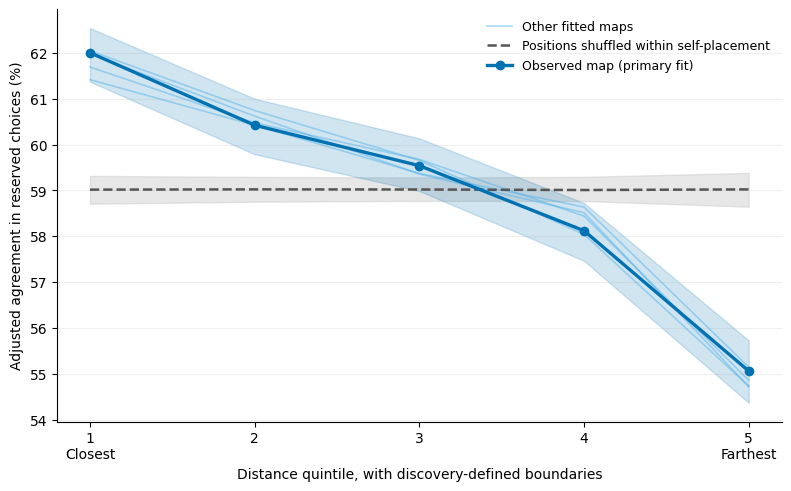

In [4]:
fig, ax = plt.subplots(figsize=(7.8, 4.8), layout='constrained')
primary_curve = global_curves.loc[global_curves.seed.eq(PRIMARY_SEED)].sort_values('quintile')
for seed in SEEDS[1:]:
    curve = global_curves.loc[global_curves.seed.eq(seed)].sort_values('quintile')
    ax.plot(curve.quintile, 100*curve.adjusted_agreement, color='#56B4E9', alpha=.5, lw=1.2,
            label='Other fitted maps' if seed == SEEDS[1] else None)
ax.fill_between(primary_curve.quintile, 100*primary_curve.shuffled_lower95, 100*primary_curve.shuffled_upper95,
                color='#bdbdbd', alpha=.35)
ax.plot(primary_curve.quintile, 100*primary_curve.shuffled_mean, color='#555555', ls='--', lw=1.8,
        label='Positions shuffled within self-placement')
ax.fill_between(primary_curve.quintile, 100*primary_curve.lower95, 100*primary_curve.upper95,
                color='#0072B2', alpha=.18)
ax.plot(primary_curve.quintile, 100*primary_curve.adjusted_agreement, color='#0072B2', marker='o', lw=2.4,
        label='Observed map (primary fit)')
ax.set_xticks(range(1, 6), ['1\nClosest', '2', '3', '4', '5\nFarthest'])
ax.set_xlabel('Distance quintile, with discovery-defined boundaries')
ax.set_ylabel('Adjusted agreement in reserved choices (%)')
ax.grid(axis='y', alpha=.2)
ax.legend(frameon=False, fontsize=9, loc='best')
show_figure(fig, 'global_concordance')

## Policy cases: observed choices and geometric stability

For each frozen proposal, estimate Near minus Far in choosing that proposal,
controlling for the opposing proposal. Near and Far always refer to the one
case anchor. The middle sector is plotted but does not enter this contrast.
Bootstrap whole people, preserving their multiple decisions. The case-3
bootstrap uses its original seed for exact reproduction. Intervals are
pointwise and conditional on the fitted map and fixed sectors.

Report total observations and the people/choices with opponents represented
in both extremes. Only the latter identify the adjusted contrast. Retain every
selected proposal, including uncertain, contrary or insufficient-support
findings. If more than 5% of bootstrap samples are unidentified, suppress the
interval and report the problem rather than manufacturing precision.

In [5]:
figure_labels = {
    37: 'Constituent assembly',
    72: 'Reduce number of provinces',
    57: 'Judicial investigation of recent human-rights violations',
    78: 'End coattail-based election of legislators',
    66: 'Limit parliamentary reelection',
    55: 'Minimum pension at least minimum wage',
    86: 'Cancel state-guaranteed student-loan debt (CAE)',
    6: 'Reverse privatization of water',
    85: 'Increase tax progressivity (tax the very rich more)',
    20: 'Reform or abolish the notary system',
    34: 'Reduce number of legislators',
    45: 'Reduce property taxes for vulnerable older adults',
}
assert set(selected_cases[3].proposal_id) | set(selected_cases[7].proposal_id) == set(figure_labels)
source_wording = pd.concat([selected_cases[label][['figure_number', 'proposal_id', 'full_text', 'role']].assign(self_placement=label) for label in [3, 7]], ignore_index=True)
source_wording['figure_label'] = source_wording.proposal_id.map(figure_labels)
show_table(source_wording, 'proposal_wording')

def observed_case_effect(frame, random_seed):
    if frame.empty:
        return {'difference': np.nan, 'lower95': np.nan, 'upper95': np.nan,
                'total_people': 0, 'total_choices': 0, 'near_people': 0, 'far_people': 0,
                'common_people': 0, 'common_choices': 0, 'shared_opponents': 0,
                'unidentified_bootstraps': CASE_BOOTSTRAPS, 'sufficient_support': False}, np.full(CASE_BOOTSTRAPS, np.nan)
    opponents, group = np.unique(frame.opponent, return_inverse=True)
    users, user = np.unique(frame.u, return_inverse=True)
    x, y = frame.near.to_numpy(float), frame.chosen.to_numpy(float)
    count = np.bincount(group)
    sum_x = np.bincount(group, weights=x)
    mixed = (sum_x > 0) & (sum_x < count)
    common = frame.loc[mixed[group]]
    def coefficient(weights):
        n = np.bincount(group, weights=weights, minlength=len(opponents))
        sx = np.bincount(group, weights=weights*x, minlength=len(opponents))
        sy = np.bincount(group, weights=weights*y, minlength=len(opponents))
        sxy = np.bincount(group, weights=weights*x*y, minlength=len(opponents))
        ok = n > 0
        denominator = np.sum(sx[ok] - sx[ok]**2/n[ok])
        numerator = np.sum(sxy[ok] - sx[ok]*sy[ok]/n[ok])
        return numerator/denominator if denominator > 1e-12 else np.nan
    effect = coefficient(np.ones(len(frame)))
    rng = np.random.default_rng(random_seed)
    draws = np.empty(CASE_BOOTSTRAPS)
    for replicate in range(CASE_BOOTSTRAPS):
        multiplicities = rng.multinomial(len(users), np.full(len(users), 1/len(users)))
        draws[replicate] = coefficient(multiplicities[user])
    valid = np.isfinite(draws)
    interval = np.quantile(draws[valid], [.025, .975]) if valid.mean() >= .95 else [np.nan, np.nan]
    near_people = frame.loc[frame.near.eq(1), 'u'].nunique()
    far_people = frame.loc[frame.near.eq(0), 'u'].nunique()
    result = {'difference': effect, 'lower95': interval[0], 'upper95': interval[1],
              'total_people': len(users), 'total_choices': len(frame), 'near_people': near_people, 'far_people': far_people,
              'common_people': common.u.nunique(), 'common_choices': len(common),
              'common_near_people': common.loc[common.near.eq(1), 'u'].nunique(),
              'common_far_people': common.loc[common.near.eq(0), 'u'].nunique(),
              'shared_opponents': int(mixed.sum()), 'unidentified_bootstraps': int((~valid).sum()),
              'sufficient_support': near_people >= MIN_PEOPLE and far_people >= MIN_PEOPLE and mixed.sum() >= MIN_SHARED_OPPONENTS}
    return result, draws

case_effect_rows, case_bootstrap_frames, case_choice_frames = [], [], []
profile_rows, assignment_frames = [], []
for label in [3, 7]:
    participant_frame = case_people[label]
    membership = pd.Series(case_sectors[label, PRIMARY_SEED], index=participant_frame.u)
    assignment = participant_frame.copy()
    for seed in SEEDS:
        assignment[f'sector_{seed}'] = case_sectors[label, seed]
    assignment_frames.append(assignment)
    heldout = confirmation.loc[confirmation.label.eq(label)].copy()
    heldout['sector'] = heldout.u.map(membership)
    for row in selected_cases[label].itertuples():
        frame = heldout.loc[(heldout.option_a.eq(row.proposal_id) | heldout.option_b.eq(row.proposal_id)) & heldout.sector.isin(['Near', 'Far'])].copy()
        frame['near'] = frame.sector.eq('Near').astype(int)
        frame['opponent'] = np.where(frame.option_a.eq(row.proposal_id), frame.b, frame.a)
        frame['chosen'] = frame.selected.eq(row.proposal_id).astype(int)
        effect, draws = observed_case_effect(frame, 20261014 if label == 3 else RANDOM_SEED)
        effect.update({'self_placement': label, 'proposal_id': row.proposal_id,
                       'figure_number': row.figure_number, 'role': row.role,
                       'figure_label': figure_labels[row.proposal_id]})
        case_effect_rows.append(effect)
        case_bootstrap_frames.append(pd.DataFrame({'self_placement': label, 'proposal_id': row.proposal_id,
                                                   'replicate': np.arange(CASE_BOOTSTRAPS), 'difference': draws}))
        case_choice_frames.append(frame.assign(target_id=row.proposal_id))
    for seed in SEEDS:
        for definition in ['Fixed 101 sectors', 'Seed-specific sectors']:
            sector_values = case_sectors[label, PRIMARY_SEED if definition == 'Fixed 101 sectors' else seed]
            for phase in ['discovery', 'confirmation']:
                for sector in SECTORS:
                    mask = participant_frame.phase.eq(phase).to_numpy() & (sector_values == sector)
                    for proposal_id in selected_cases[label].proposal_id:
                        rank = case_rankings[label, seed][mask, proposal_index.loc[proposal_id]].mean()
                        profile_rows.append({'self_placement': label, 'seed': seed, 'membership': definition,
                                             'phase': phase, 'sector': sector, 'proposal_id': proposal_id,
                                             'mean_rank': rank, 'people': int(mask.sum())})

case_effects = pd.DataFrame(case_effect_rows)
case_bootstrap = pd.concat(case_bootstrap_frames, ignore_index=True)
case_analysis_choices = pd.concat(case_choice_frames, ignore_index=True)
case_profiles_all_fits = pd.DataFrame(profile_rows)
case_assignments = pd.concat(assignment_frames, ignore_index=True)
focal = case_effects.loc[case_effects.self_placement.eq(3) & case_effects.proposal_id.eq(37)].iloc[0]
assert np.allclose([focal.difference, focal.lower95, focal.upper95], [.3240072202166066, .1528483215225521, .4867683372538718], atol=1e-12)
show_table(case_effects, 'case_choice_contrasts')
show_table(case_bootstrap, 'case_bootstrap')
show_table(case_profiles_all_fits, 'case_profiles_all_fits')
show_table(case_assignments, 'case_sector_memberships')
display(case_analysis_choices)
case_analysis_choices.to_parquet(TABLES / 'map20_case_confirmation_choices.parquet', index=False)

case_gaps = case_profiles_all_fits.pivot(index=['self_placement', 'seed', 'membership', 'phase', 'proposal_id'], columns='sector', values='mean_rank').reset_index()
case_gaps['gap_far_minus_near'] = case_gaps.Far - case_gaps.Near
stability_rows = []
for (label, membership, phase, proposal_id), group in case_gaps.groupby(['self_placement', 'membership', 'phase', 'proposal_id']):
    original = selected_cases[label].set_index('proposal_id').loc[proposal_id]
    same_sign = int((np.sign(group.gap_far_minus_near) == np.sign(original.gap_far_minus_near)).sum())
    shared_rule = int(((group.Near <= PRIORITY_CUTOFF) & (group.Far <= PRIORITY_CUTOFF) & (group.gap_far_minus_near.abs() <= SHARED_GAP)).sum())
    stability_rows.append({'self_placement': label, 'membership': membership, 'phase': phase,
                           'proposal_id': proposal_id, 'role': original.role,
                           'same_discovery_direction_fits': same_sign,
                           'min_rank_gap': group.gap_far_minus_near.min(), 'max_rank_gap': group.gap_far_minus_near.max(),
                           'shared_priority_rule_fits': shared_rule,
                           'stable_interpretation': shared_rule == 5 if original.role == 'Shared' else same_sign == 5})
case_stability = pd.DataFrame(stability_rows)
show_table(case_stability, 'case_stability')
primary_stability = case_stability.loc[case_stability.membership.eq('Fixed 101 sectors') & case_stability.phase.eq('confirmation')]
case_summary = case_effects.merge(primary_stability[['self_placement', 'proposal_id', 'same_discovery_direction_fits', 'shared_priority_rule_fits', 'stable_interpretation']], on=['self_placement', 'proposal_id'], validate='one_to_one')
for field in ['difference', 'lower95', 'upper95']:
    case_summary[field + '_pp'] = 100*case_summary[field]
case_summary_publication = case_summary[['self_placement', 'proposal_id', 'figure_label', 'difference_pp', 'lower95_pp', 'upper95_pp', 'common_people', 'common_choices', 'same_discovery_direction_fits', 'stable_interpretation', 'sufficient_support']].copy()
show_table(case_summary_publication, 'case_summary', publication=True)

,figure_number,proposal_id,full_text,role,self_placement,figure_label
0,1,37,Asamblea Constituyente,Focal,3,Constituent assembly
1,2,72,Reducir Número de Provincias,Near-distinctive,3,Reduce number of provinces
2,3,57,Investigación Judicial de Violaciones Reciente...,Near-distinctive,3,Judicial investigation of recent human-rights ...
3,4,78,Eliminación de elección de parlamentarios por ...,Far-distinctive,3,End coattail-based election of legislators
4,5,66,Limitar la Reeleción de Parlamentarios y Parla...,Far-distinctive,3,Limit parliamentary reelection
5,6,55,Pensión Mínima Igual o Mayor al Sueldo Mínimo,Shared,3,Minimum pension at least minimum wage
6,1,86,Condonación de las deudas del Crédito con Aval...,Focal,7,Cancel state-guaranteed student-loan debt (CAE)
7,2,6,Desprivatización del Agua,Near-distinctive,7,Reverse privatization of water
8,3,85,Aumentar progresividad de impuestos (más impue...,Near-distinctive,7,Increase tax progressivity (tax the very rich ...
9,4,20,Reforma o fin de sistema de Notarios,Far-distinctive,7,Reform or abolish the notary system


,difference,lower95,upper95,total_people,total_choices,near_people,far_people,common_people,common_choices,common_near_people,common_far_people,shared_opponents,unidentified_bootstraps,sufficient_support,self_placement,proposal_id,figure_number,role,figure_label
0,0.324007,0.152848,0.486768,200,219,123,77,135,145,75,60,45,0,True,3,37,1,Focal,Constituent assembly
1,-0.115707,-0.244993,0.029863,187,223,131,56,131,148,79,52,42,0,True,3,72,2,Near-distinctive,Reduce number of provinces
2,0.230899,0.071146,0.365411,212,239,126,86,167,182,96,71,48,0,True,3,57,3,Near-distinctive,Judicial investigation of recent human-rights ...
3,-0.115548,-0.309773,0.075483,192,227,103,89,130,150,72,58,48,0,True,3,78,4,Far-distinctive,End coattail-based election of legislators
4,-0.099041,-0.308090,0.118126,183,205,113,70,126,139,79,47,41,0,True,3,66,5,Far-distinctive,Limit parliamentary reelection
5,-0.006955,-0.131634,0.131973,217,250,137,80,167,183,94,73,50,0,True,3,55,6,Shared,Minimum pension at least minimum wage
6,0.150352,-0.105021,0.397335,140,160,57,83,90,97,37,53,31,0,True,7,86,1,Focal,Cancel state-guaranteed student-loan debt (CAE)
7,0.207065,-0.105391,0.535440,126,143,42,84,61,62,30,31,23,0,True,7,6,2,Near-distinctive,Reverse privatization of water
8,0.387990,0.162786,0.577334,154,180,56,98,103,114,47,56,36,0,True,7,85,3,Near-distinctive,Increase tax progressivity (tax the very rich ...
9,-0.209877,-0.493282,0.115965,135,155,44,91,57,61,25,32,22,0,True,7,20,4,Far-distinctive,Reform or abolish the notary system


,self_placement,proposal_id,replicate,difference
0,3,37,0,0.318153
1,3,37,1,0.386687
2,3,37,2,0.368322
3,3,37,3,0.211205
4,3,37,4,0.501112
...,...,...,...,...
23995,7,45,1995,-0.076142
23996,7,45,1996,-0.143509
23997,7,45,1997,-0.140119
23998,7,45,1998,-0.127462


,self_placement,seed,membership,phase,sector,proposal_id,mean_rank,people
0,3,101,Fixed 101 sectors,discovery,Near,37,2.898026,608
1,3,101,Fixed 101 sectors,discovery,Near,72,12.942434,608
2,3,101,Fixed 101 sectors,discovery,Near,57,4.205592,608
3,3,101,Fixed 101 sectors,discovery,Near,78,49.156250,608
4,3,101,Fixed 101 sectors,discovery,Near,66,46.271382,608
...,...,...,...,...,...,...,...,...
715,7,501,Seed-specific sectors,confirmation,Far,6,60.101449,483
716,7,501,Seed-specific sectors,confirmation,Far,85,50.333333,483
717,7,501,Seed-specific sectors,confirmation,Far,20,26.082816,483
718,7,501,Seed-specific sectors,confirmation,Far,34,36.904762,483


,uuid,politica,u,phase,sector_101,sector_201,sector_301,sector_401,sector_501
0,000629ba-44c0-47c1-b2b2-abe4f0ee808f,3,3,discovery,Middle,Far,Far,Far,Far
1,0006b923-77a6-40c1-95e0-f98b817bcab2,3,4,discovery,Far,Far,Far,Far,Far
2,0019afe7-03fc-40b2-a8f1-6216c2943613,3,16,confirmation,Middle,Near,Near,Near,Near
3,0040473a-c6fa-4a5c-8649-2b00f72349a2,3,40,confirmation,Near,Near,Near,Middle,Near
4,005d8525-7b65-49f3-8f20-9f30cc43d09c,3,60,discovery,Near,Near,Middle,Far,Far
...,...,...,...,...,...,...,...,...,...
6763,ff3e1f06-2a8a-4606-ae71-2cab079140d3,7,47442,confirmation,Near,Middle,Near,Near,Near
6764,ff4b2172-3187-4a86-8a8a-0e823776ed04,7,47449,confirmation,Far,Middle,Near,Middle,Middle
6765,ffd1358b-64db-4603-8e62-9a638c00ae60,7,47547,discovery,Far,Middle,Middle,Middle,Middle
6766,ffdd7eff-a598-4406-b445-ee1d7b61b039,7,47556,confirmation,Near,Near,Far,Near,Near


,id,uuid,option_a,option_b,selected,datetime,split,u,a,b,lo,hi,label,phase,sector,near,opponent,chosen,target_id
0,20304,85defd8b-8a5d-419d-8a4c-7cb09b83bb36,37,34,34,2019-10-24 14:28:19,test,24873,36,33,33,36,3,confirmation,Far,0,33,0,37
1,20537,85defd8b-8a5d-419d-8a4c-7cb09b83bb36,70,37,70,2019-10-24 14:28:39,test,24873,69,36,36,69,3,confirmation,Far,0,69,0,37
2,27304,5cc479bf-c2fe-4d6d-9343-aa05e9b843f2,19,37,37,2019-10-24 14:38:37,test,17259,18,36,18,36,3,confirmation,Near,1,18,1,37
3,40992,30ddf8fa-02d6-454d-9e20-cdaffb2658a5,31,37,37,2019-10-24 14:56:30,test,9136,30,36,30,36,3,confirmation,Near,1,30,1,37
4,57401,5c3712af-afeb-48a0-a339-f4075f524fa6,84,37,37,2019-10-24 15:13:39,test,17151,83,36,36,83,3,confirmation,Near,1,83,1,37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2373,3630676,f6476902-4421-4395-bb0a-c0ae7c960457,50,45,50,2019-10-30 23:26:19,test,45761,49,44,44,49,7,confirmation,Far,0,49,0,45
2374,3638549,6622f92d-9d33-46ce-baf9-fa9a3226824a,22,45,22,2019-10-30 23:37:58,test,18997,21,44,21,44,7,confirmation,Far,0,21,0,45
2375,3646305,bed0eefc-ea14-472e-9230-395667952a60,84,45,45,2019-10-30 23:50:20,test,35497,83,44,44,83,7,confirmation,Far,0,83,1,45
2376,3671137,4c82463a-a75c-44a3-a909-27ab14dbab98,45,17,17,2019-10-31 01:04:37,test,14242,44,16,16,44,7,confirmation,Far,0,16,0,45


,self_placement,membership,phase,proposal_id,role,same_discovery_direction_fits,min_rank_gap,max_rank_gap,shared_priority_rule_fits,stable_interpretation
0,3,Fixed 101 sectors,confirmation,37,Focal,5,44.175227,65.811540,0,True
1,3,Fixed 101 sectors,confirmation,55,Shared,1,-1.696685,3.895291,5,True
2,3,Fixed 101 sectors,confirmation,57,Near-distinctive,5,44.102658,63.950150,0,True
3,3,Fixed 101 sectors,confirmation,66,Far-distinctive,5,-15.701703,-12.645696,0,True
4,3,Fixed 101 sectors,confirmation,72,Near-distinctive,2,-6.102552,72.796695,0,False
5,3,Fixed 101 sectors,confirmation,78,Far-distinctive,5,-19.004922,-12.571647,0,True
6,3,Fixed 101 sectors,discovery,37,Focal,5,43.310077,63.530545,0,True
7,3,Fixed 101 sectors,discovery,55,Shared,3,-2.364078,2.115915,5,True
8,3,Fixed 101 sectors,discovery,57,Near-distinctive,5,43.212668,63.129383,0,True
9,3,Fixed 101 sectors,discovery,66,Far-distinctive,5,-17.616209,-12.943744,0,True


,self_placement,proposal_id,figure_label,difference_pp,lower95_pp,upper95_pp,common_people,common_choices,same_discovery_direction_fits,stable_interpretation,sufficient_support
0,3,37,Constituent assembly,32.400722,15.284832,48.676834,135,145,5,True,True
1,3,72,Reduce number of provinces,-11.570689,-24.499256,2.986329,131,148,2,False,True
2,3,57,Judicial investigation of recent human-rights ...,23.089922,7.114616,36.541128,167,182,5,True,True
3,3,78,End coattail-based election of legislators,-11.554779,-30.977350,7.548290,130,150,5,True,True
4,3,66,Limit parliamentary reelection,-9.904075,-30.808978,11.812645,126,139,5,True,True
5,3,55,Minimum pension at least minimum wage,-0.695536,-13.163415,13.197272,167,183,1,True,True
6,7,86,Cancel state-guaranteed student-loan debt (CAE),15.035239,-10.502108,39.733532,90,97,5,True,True
7,7,6,Reverse privatization of water,20.706456,-10.539135,53.543986,61,62,5,True,True
8,7,85,Increase tax progressivity (tax the very rich ...,38.798951,16.278603,57.733393,103,114,5,True,True
9,7,20,Reform or abolish the notary system,-20.987654,-49.328169,11.596494,57,61,5,True,True


## Case figures

A locates the same participants and selected proposals. B reports the mean
within-person rank among all 90 alternatives, with 1 denoting greatest inferred
priority. C reports the observed Near-minus-Far choice contrast adjusted for
opponent. The count column reports common-opponent people and choices, not the
larger totals. Every selected proposal remains visible. A dagger marks a rank
interpretation that is not stable across all five fits. Similar inferred ranks
or an interval crossing zero do not establish consensus or equivalence.

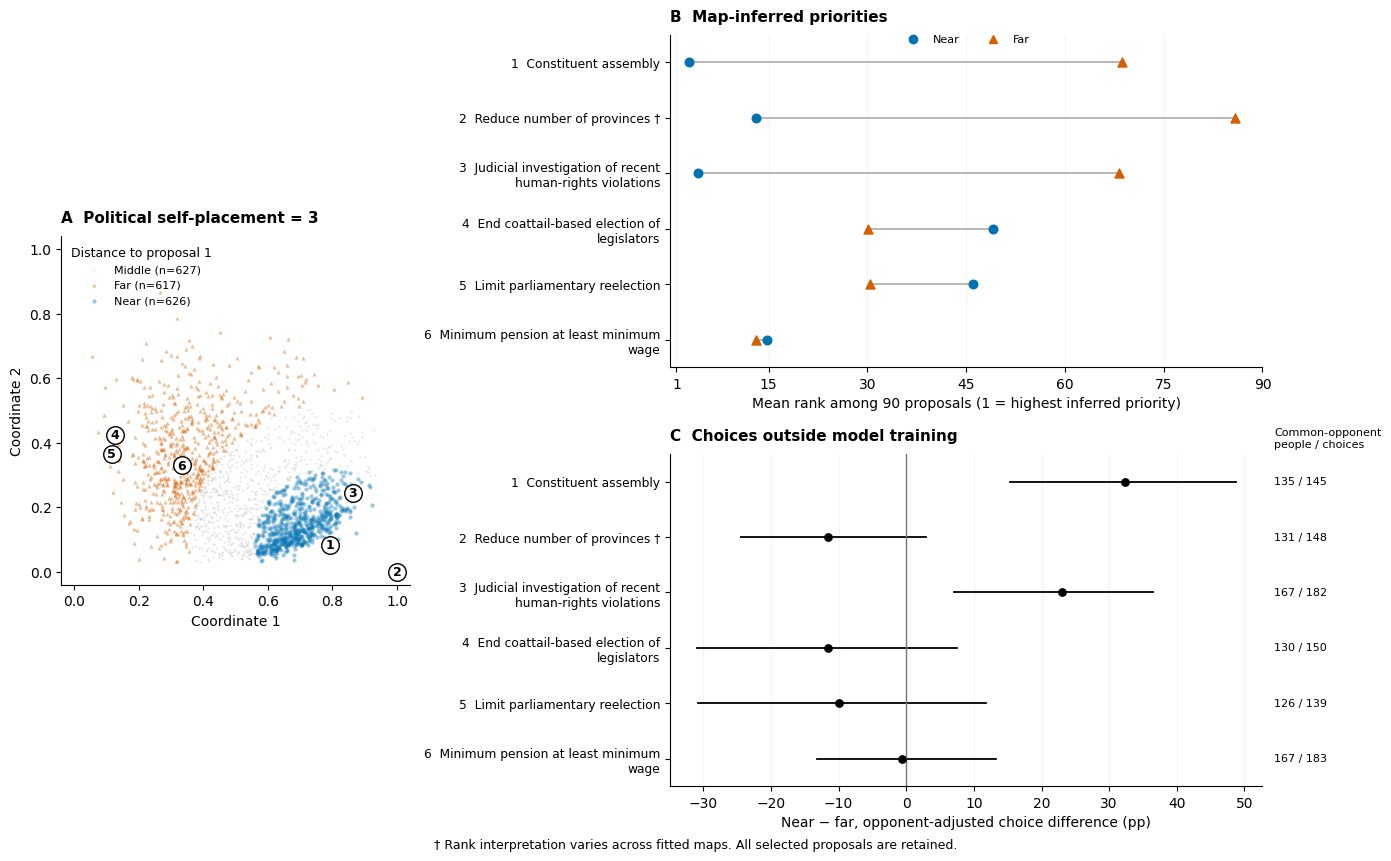

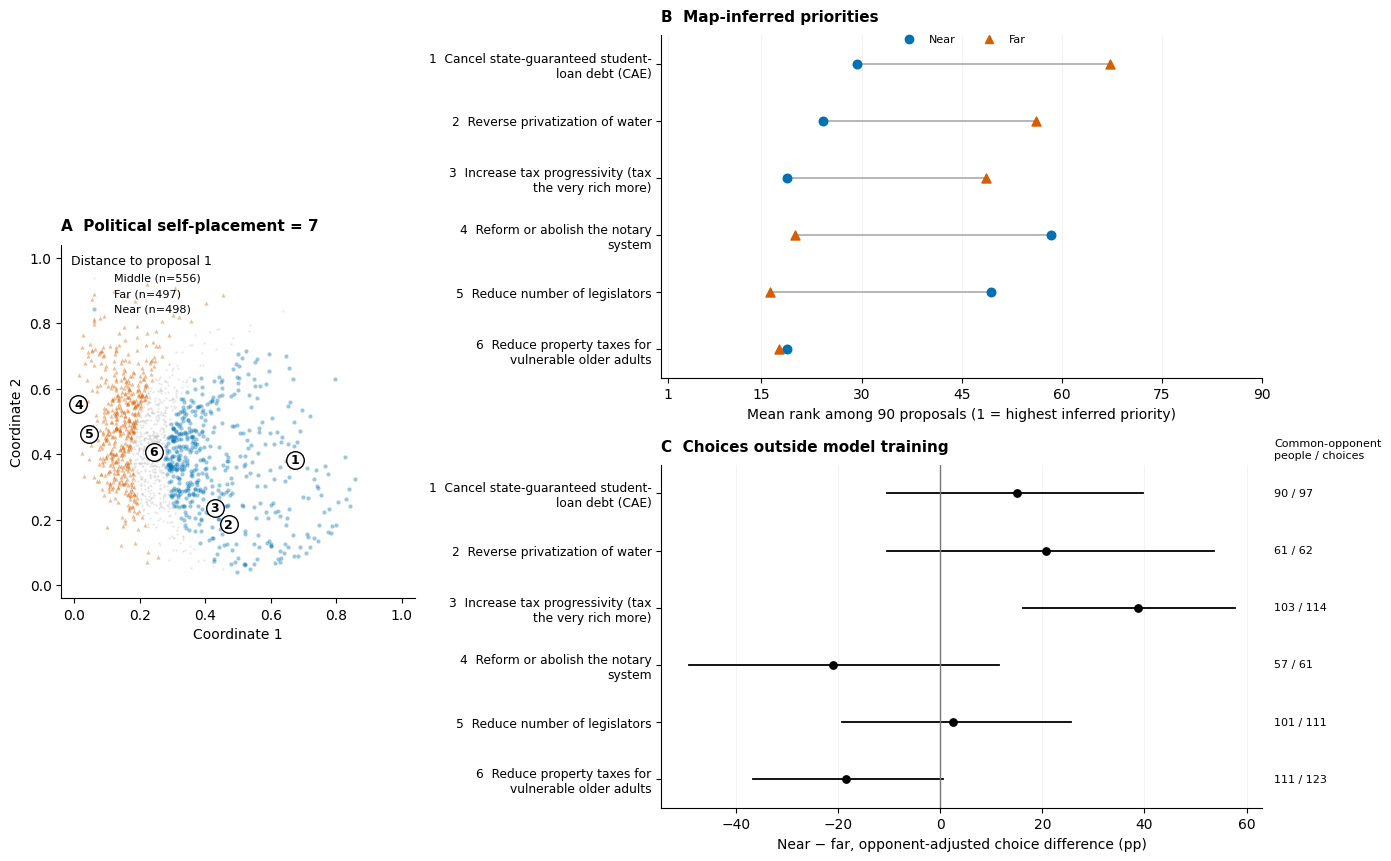

In [6]:
def case_figure(label):
    selected = selected_cases[label]
    people = case_people[label]
    mask = people.phase.eq('confirmation').to_numpy()
    sectors = case_sectors[label, PRIMARY_SEED][mask]
    if label == 3:
        # The exact frozen coordinates were already loaded into case_distances.
        plot_coords = pd.read_csv(CASE3 / '101/coordinates.csv', float_precision='round_trip')[['z1', 'z2']].to_numpy()[mask]
    else:
        plot_coords = coordinates[PRIMARY_SEED][people.loc[mask, 'u']]
    profile = case_profiles_all_fits.loc[case_profiles_all_fits.self_placement.eq(label) & case_profiles_all_fits.seed.eq(PRIMARY_SEED) & case_profiles_all_fits.membership.eq('Fixed 101 sectors') & case_profiles_all_fits.phase.eq('confirmation')]
    effects = case_summary.loc[case_summary.self_placement.eq(label)].sort_values('figure_number')
    fig = plt.figure(figsize=(13.8, 8.5), layout='constrained')
    grid = fig.add_gridspec(2, 2, width_ratios=[1., 1.7])
    map_axis = fig.add_subplot(grid[:, 0])
    rank_axis = fig.add_subplot(grid[0, 1])
    choice_axis = fig.add_subplot(grid[1, 1])
    for sector, marker in [('Middle', '.'), ('Far', '^'), ('Near', 'o')]:
        use = sectors == sector
        map_axis.scatter(plot_coords[use, 1], plot_coords[use, 0], s=9, alpha=.4,
                         color=COLORS[sector], marker=marker, linewidths=0,
                         label=f'{sector} (n={use.sum():,})')
    for row in selected.itertuples():
        position = proposal_coordinates[PRIMARY_SEED][proposal_index.loc[row.proposal_id]]
        map_axis.scatter(position[1], position[0], s=160, facecolor='white', edgecolor='black', linewidth=1., zorder=8)
        map_axis.text(position[1], position[0], str(row.figure_number), ha='center', va='center', fontsize=9, fontweight='bold', zorder=9)
    map_axis.set(xlabel='Coordinate 1', ylabel='Coordinate 2', xlim=(-.04, 1.04), ylim=(-.04, 1.04), aspect='equal')
    map_axis.text(0, 1.04, f'A  Political self-placement = {label}', transform=map_axis.transAxes, fontsize=11, fontweight='bold')
    map_axis.legend(frameon=False, loc='upper left', fontsize=8, title='Distance to proposal 1', title_fontsize=9)
    labels_plot = []
    for row in effects.itertuples():
        suffix = ' †' if not row.stable_interpretation else ''
        labels_plot.append(f'{row.figure_number}  ' + textwrap.fill(row.figure_label + suffix, 32))
        ranks = profile.loc[profile.proposal_id.eq(row.proposal_id)].set_index('sector').mean_rank
        y = row.figure_number - 1
        rank_axis.plot([ranks.Near, ranks.Far], [y, y], color='#aaaaaa', lw=1.2)
        rank_axis.scatter(ranks.Near, y, color=COLORS['Near'], marker='o', s=38, zorder=3)
        rank_axis.scatter(ranks.Far, y, color=COLORS['Far'], marker='^', s=42, zorder=3)
        if np.isfinite(row.lower95) and np.isfinite(row.upper95):
            choice_axis.plot([100*row.lower95, 100*row.upper95], [y, y], color='black', lw=1.3)
        if np.isfinite(row.difference):
            choice_axis.scatter(100*row.difference, y, s=28, edgecolor='black', facecolor='black' if row.sufficient_support else 'white', zorder=3)
        else:
            choice_axis.text(0, y, 'not identified', ha='center', fontsize=8)
        choice_axis.text(1.02, y, f'{row.common_people} / {row.common_choices}', transform=choice_axis.get_yaxis_transform(), ha='left', va='center', fontsize=8)
    for axis in [rank_axis, choice_axis]:
        axis.set_yticks(np.arange(len(selected)), labels_plot, fontsize=8.8)
        axis.set_ylim(len(selected)-.5, -.5)
        axis.grid(axis='x', alpha=.15)
    rank_axis.set(xlim=(0, 90), xlabel='Mean rank among 90 proposals (1 = highest inferred priority)')
    rank_axis.set_xticks([1, 15, 30, 45, 60, 75, 90])
    rank_axis.text(0, 1.04, 'B  Map-inferred priorities', transform=rank_axis.transAxes, fontsize=11, fontweight='bold')
    rank_axis.legend(handles=[Line2D([0], [0], marker='o', ls='', color=COLORS['Near'], label='Near'),
                              Line2D([0], [0], marker='^', ls='', color=COLORS['Far'], label='Far')],
                     frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(.5, 1.03), fontsize=8)
    choice_axis.axvline(0, color='#777777', lw=1)
    choice_axis.set_xlabel('Near − far, opponent-adjusted choice difference (pp)')
    choice_axis.text(0, 1.04, 'C  Choices outside model training', transform=choice_axis.transAxes, fontsize=11, fontweight='bold')
    choice_axis.text(1.02, 1.02, 'Common-opponent\npeople / choices', transform=choice_axis.transAxes, fontsize=8, ha='left')
    if (~effects.stable_interpretation).any():
        fig.supxlabel('† Rank interpretation varies across fitted maps. All selected proposals are retained.', fontsize=9)
    return fig

for label in [3, 7]:
    figure = case_figure(label)
    show_figure(figure, f'case_selfplacement_{label}')

## Interpretation and reproducibility

Read the global result and both cases together. A negative global distance
association would support a behavioral interpretation of proximity across the
evaluated sample. A case is supported only where the reserved choices and the
geometric direction agree. Five fits evaluate sensitivity to initialization,
not five independent datasets. These checks do not identify discrete political
groups, establish causality or validate every geometric detail.

In [7]:
primary = global_summary.loc[global_summary.seed.eq(PRIMARY_SEED)].iloc[0]
direction_fits = int(global_summary.closer_advantage_pp.gt(0).sum())
global_sentence = (f'Among {len(global_people):,} confirmation participants with unambiguous political self-placement, '
                   f'the analysis compared {len(confirmation_dyads):,} response dyads facing the same proposal pair and reporting the same label. '
                   f'In the primary fit, the fixed-effect linear model estimated {primary.closer_advantage_pp:.1f} percentage points '
                   f'more agreement for a distance decrease from the discovery 90th to 10th percentile '
                   f'(95% participant-bootstrap interval {primary.lower95_pp:.1f} to {primary.upper95_pp:.1f}, '
                   f'one-sided within-label position-permutation p={primary.permutation_p_one_sided:.3f}). '
                   f'The direction favored closer people in {direction_fits}/5 fitted maps. '
                   f'Self-placement 5 contributed {100*label5_dyad_share:.1f}% of eligible response dyads, so this pooled result does not establish the association separately at every label.')
case_sentences = []
for label in [3, 7]:
    selected = selected_cases[label].set_index('proposal_id')
    results = case_summary.loc[case_summary.self_placement.eq(label)].sort_values('figure_number')
    supported = []
    for row in results.itertuples():
        direction = np.sign(selected.loc[row.proposal_id, 'gap_far_minus_near'])
        supported_interval = (row.lower95 > 0 and direction > 0) or (row.upper95 < 0 and direction < 0)
        if row.role != 'Shared' and row.stable_interpretation and row.sufficient_support and supported_interval:
            supported.append(f'{row.figure_label} ({100*row.difference:+.1f} pp, 95% interval {100*row.lower95:.1f} to {100*row.upper95:.1f})')
    statement = (f'For self-placement {label}, the sector anchor was {figure_labels[anchors[label]]}. '
                 f'Stable map-inferred contrasts with directionally consistent reserved-choice intervals excluding zero were: '
                 + ('; '.join(supported) if supported else 'none') + '. All other selected estimates remain reported.')
    case_sentences.append(statement)
interpretation = '\n\n'.join([global_sentence] + case_sentences + [
    'Intervals are pointwise and conditional on fitted coordinates, selected cases and the observed alternative set. '
    'The global estimand weights eligible response dyads equally, and the same people appear in multiple dyads. '
    'The participant bootstrap accounts for shared endpoints. The permutation is a correspondence reference under '
    'within-label exchangeability. The historical test data were previously consulted, so this is secondary evidence. '
    'These results do not establish causal effects, natural political groups, equivalent support for shared priorities or universal reliability of map geometry.'
])
interpretation = interpretation.replace('; ', '. ')
display(Markdown(interpretation))
(DIAGNOSTICS / 'map20_interpretation.md').write_text(interpretation)

global_caption = ('Concordance of reserved choices and distance in the Chilean DYNAMAP map. Each response dyad joins two distinct '
                  'confirmation participants with the same exact self-placement who evaluated the same unordered pair of proposals. '
                  'Quintile boundaries were fixed using discovery distances. Curves are category predictions from a linear probability '
                  'model with self-placement-by-proposal-pair fixed effects, standardized to the eligible confirmation-dyad composition. '
                  'The primary curve and its pointwise 95% band use fit 101 and 1,000 participant bootstrap resamples with shared weights '
                  'across all responses and both dyad endpoints. Thin curves show the other four maps. The dashed curve and gray envelope '
                  'show the mean and pointwise 95% range across 499 within-label person-position permutations in fit 101. The envelope is '
                  'a permutation reference, not a confidence interval for the observed curve. Distance-bin probabilities are a descriptive '
                  'model summary. The prespecified continuous distance contrast is reported separately. The evaluation is secondary and '
                  'conditional on the fitted maps and the observed set of alternatives.')
global_caption += f' Self-placement 5 contributes {100*label5_dyad_share:.1f}% of eligible dyads. The pooled estimand weights response dyads equally and does not establish the pattern at every self-placement.'
case_caption = ('Relative priorities within political self-placement 3 or 7. A shows confirmation participants and frozen selected '
                'proposals. Sectors use discovery terciles of distance to proposal 1, and the same sectors are used for every row. '
                'B shows mean within-person ranks among all 90 proposals, with lower rank denoting higher inferred relative priority. '
                'C shows observed Near-minus-Far differences in choosing each proposal, adjusted for the opposing proposal, with '
                'pointwise 95% participant-bootstrap percentile intervals from 2,000 resamples. Counts report people and choices with '
                'opponents represented in both extreme sectors. Hollow points indicate insufficient support under the frozen rule. '
                'A dagger marks a rank interpretation that fails the same-direction or shared-priority criterion in at least one of '
                'the five maps with principal-map membership held fixed. All selected proposals are retained. Case 3 preserves the '
                'previous selection. Case 7 selects its anchor by median discovery rank IQR across maps among exposure-eligible '
                'proposals, then applies the same limited proposal-selection rule. No case-7 confirmation outcomes inform selection. '
                'The sectors describe parts of a continuous map and are not natural political classes. Similar ranks or uncertain '
                'choice differences do not establish consensus or equivalence.')
captions = '## Global figure\n\n' + global_caption + '\n\n## Case figures\n\n' + case_caption
display(Markdown(captions))
(DIAGNOSTICS / 'map20_figure_captions.md').write_text(captions)

validation = pd.DataFrame([
    {'check': 'original_split_and_age_eligibility_retained', 'passed': True},
    {'check': 'self_placement_5_included_in_global', 'passed': bool((global_coverage.self_placement == 5).any())},
    {'check': 'case3_original_selection_and_effect_reproduced', 'passed': True},
    {'check': 'case7_selection_lock_unchanged', 'passed': hashlib.sha256(selection_payload.encode()).hexdigest() == selection_hash},
    {'check': 'all_selected_proposals_retained', 'passed': len(case_effects) == sum(len(v) for v in selected_cases.values())},
    {'check': 'global_bootstrap_and_permutations_finite', 'passed': bool(np.isfinite(global_bootstrap.select_dtypes('number')).all().all() and np.isfinite(global_permutations.select_dtypes('number')).all().all())},
    {'check': 'case_bootstrap_failures_reported', 'passed': bool((case_effects.unidentified_bootstraps >= 0).all())},
])
assert validation.passed.all()
show_table(validation, 'verification')
manifest = {'inputs': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in input_paths},
            'selection_sha256': selection_hash, 'seeds': SEEDS,
            'environment': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                            'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__},
            'parameters': {'global_bootstraps': GLOBAL_BOOTSTRAPS, 'position_permutations': POSITION_PERMUTATIONS,
                           'case_bootstraps': CASE_BOOTSTRAPS, 'random_seed': RANDOM_SEED},
            'outputs': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                        for directory in [TABLES, LATEX, FIGURES, DIAGNOSTICS]
                        for path in sorted(directory.glob('map20_*')) if path.is_file() and path.name != 'map20_manifest.json'}}
display(manifest)
(DIAGNOSTICS / 'map20_manifest.json').write_text(json.dumps(manifest, indent=2))

Out[7]: 8517


Among 18,586 confirmation participants with unambiguous political self-placement, the analysis compared 521,714 response dyads facing the same proposal pair and reporting the same label. In the primary fit, the fixed-effect linear model estimated 6.8 percentage points more agreement for a distance decrease from the discovery 90th to 10th percentile (95% participant-bootstrap interval 6.0 to 7.5, one-sided within-label position-permutation p=0.002). The direction favored closer people in 5/5 fitted maps. Self-placement 5 contributed 80.5% of eligible response dyads, so this pooled result does not establish the association separately at every label.

For self-placement 3, the sector anchor was Constituent assembly. Stable map-inferred contrasts with directionally consistent reserved-choice intervals excluding zero were: Constituent assembly (+32.4 pp, 95% interval 15.3 to 48.7). Judicial investigation of recent human-rights violations (+23.1 pp, 95% interval 7.1 to 36.5). All other selected estimates remain reported.

For self-placement 7, the sector anchor was Cancel state-guaranteed student-loan debt (CAE). Stable map-inferred contrasts with directionally consistent reserved-choice intervals excluding zero were: Increase tax progressivity (tax the very rich more) (+38.8 pp, 95% interval 16.3 to 57.7). All other selected estimates remain reported.

Intervals are pointwise and conditional on fitted coordinates, selected cases and the observed alternative set. The global estimand weights eligible response dyads equally, and the same people appear in multiple dyads. The participant bootstrap accounts for shared endpoints. The permutation is a correspondence reference under within-label exchangeability. The historical test data were previously consulted, so this is secondary evidence. These results do not establish causal effects, natural political groups, equivalent support for shared priorities or universal reliability of map geometry.

## Global figure

Concordance of reserved choices and distance in the Chilean DYNAMAP map. Each response dyad joins two distinct confirmation participants with the same exact self-placement who evaluated the same unordered pair of proposals. Quintile boundaries were fixed using discovery distances. Curves are category predictions from a linear probability model with self-placement-by-proposal-pair fixed effects, standardized to the eligible confirmation-dyad composition. The primary curve and its pointwise 95% band use fit 101 and 1,000 participant bootstrap resamples with shared weights across all responses and both dyad endpoints. Thin curves show the other four maps. The dashed curve and gray envelope show the mean and pointwise 95% range across 499 within-label person-position permutations in fit 101. The envelope is a permutation reference, not a confidence interval for the observed curve. Distance-bin probabilities are a descriptive model summary. The prespecified continuous distance contrast is reported separately. The evaluation is secondary and conditional on the fitted maps and the observed set of alternatives. Self-placement 5 contributes 80.5% of eligible dyads. The pooled estimand weights response dyads equally and does not establish the pattern at every self-placement.

## Case figures

Relative priorities within political self-placement 3 or 7. A shows confirmation participants and frozen selected proposals. Sectors use discovery terciles of distance to proposal 1, and the same sectors are used for every row. B shows mean within-person ranks among all 90 proposals, with lower rank denoting higher inferred relative priority. C shows observed Near-minus-Far differences in choosing each proposal, adjusted for the opposing proposal, with pointwise 95% participant-bootstrap percentile intervals from 2,000 resamples. Counts report people and choices with opponents represented in both extreme sectors. Hollow points indicate insufficient support under the frozen rule. A dagger marks a rank interpretation that fails the same-direction or shared-priority criterion in at least one of the five maps with principal-map membership held fixed. All selected proposals are retained. Case 3 preserves the previous selection. Case 7 selects its anchor by median discovery rank IQR across maps among exposure-eligible proposals, then applies the same limited proposal-selection rule. No case-7 confirmation outcomes inform selection. The sectors describe parts of a continuous map and are not natural political classes. Similar ranks or uncertain choice differences do not establish consensus or equivalence.

,check,passed
0,original_split_and_age_eligibility_retained,True
1,self_placement_5_included_in_global,True
2,case3_original_selection_and_effect_reproduced,True
3,case7_selection_lock_unchanged,True
4,all_selected_proposals_retained,True
5,global_bootstrap_and_permutations_finite,True
6,case_bootstrap_failures_reported,True


{'inputs': {'outputs/models/Chile_dim2_seed101/coordsU.csv': '3ac15cc2d5f05e21056d0b9a009d981efaf98be5d85f7f0dac55735825b97e2f',
  'outputs/models/Chile_dim2_seed101/coordsP.csv': 'fa482a1c94bdfa9869065d05512a70d24535abc43ee51ae9e03445ed987e8bb8',
  'outputs/models/Chile_dim2_seed201/coordsU.csv': '67f4bcaed5e3eaed28c18020ec0f753d82e46b6b2f4152ca6c42ea1b2e50877a',
  'outputs/models/Chile_dim2_seed201/coordsP.csv': '4eb551d5301a83ac430738a887d59425072e91f008822a2b357ae45125768f4d',
  'outputs/models/Chile_dim2_seed301/coordsU.csv': '009ffc2008832ce201309a485ed845e5e7041da085409bfeb12cb123a9024a2a',
  'outputs/models/Chile_dim2_seed301/coordsP.csv': '31c48974a73ceea933287e60e5045b14b7db1d82242f5dc08d50c50c52cf9c10',
  'outputs/models/Chile_dim2_seed401/coordsU.csv': 'fc1c01dd1c7130107dd97ede2ebf651c3eae13a2597f11905539cfdfe7bdbef7',
  'outputs/models/Chile_dim2_seed401/coordsP.csv': '2dffbf322672ddb01c0b9121c8778543360af502149fbd922f0a9fd25c03cbfb',
  'outputs/models/Chile_dim2_seed501/c